# Video Game Sales Prediction on Steam Data
## Notebook 5 — Modification 2: Log-Transformed Target and Gradient Boosting

**Motivation.** The baseline (Notebook 3) found that a few very popular games control both model fitting and
evaluation. The 20 test games with 10M+ owners, 0.13% of the test set, caused up to 96% of the squared error.
Linear Regression predicted negative owners for 39% of games, and the default Decision Tree and Random Forest
overfitted (Section 8.3, issues 1–6). Notebook 4 showed that these games distort the fitted models, not only
the metrics. It concluded that the next modification should be a logarithmic target, which reduces their
influence without removing any game.

**Purpose.** Starting from the baseline, three factors are changed **one at a time**, so that each change can
be credited with its own effect:

| Step | Change | Everything else |
|---|---|---|
| Baseline | Owners in millions; mean baseline, Linear Regression, Decision Tree, Random Forest (Notebook 3) | — |
| Step 1 | **Target:** log1p(owners) instead of owners in millions | As the baseline |
| Step 2 | **Model:** Gradient Boosting instead of Random Forest | As Step 1 |
| Step 3 | **Conversion back to owners:** smearing correction | As Step 2 (same fitted model) |

The baseline's 42 release-time features, random 80/20 split, 5-fold cross-validation and default model settings
are kept, and nothing is tuned. The test set is used once, in Section 10.6. The same steps are recorded as
experiments E00–E03 in `experiments/EXPERIMENT_LOG.md`, and this notebook reproduces their numbers.

**Result in brief.** Cross-validated R² on the log scale rises from −0.12 for the baseline Random Forest to 0.44 for Gradient
Boosting on the log target, and the test set confirms it (0.43). Mean absolute error falls by a third, from
0.155 to 0.104 million owners. On the original owner scale R² stays below 0.1. The 20 test games with 10M+
owners still produce 97% of the squared error, and store-page features cannot tell how big a hit will be
(Sections 10.5–10.7). Section 10.9 summarises the progress in Figure 18 and Table 24.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, train_test_split
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
MODEL_ORDER = ["Baseline (mean)", "Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]
MODEL_COLORS = dict(zip(MODEL_ORDER, [GREY, BLUE, ORANGE, GREEN, PURPLE]))
RANDOM_STATE = 42


def range_label(text):
    # "20000 - 50000" -> "20k–50k"; "1000000 - 2000000" -> "1M–2M"
    def short(n):
        n = int(n)
        if n >= 1_000_000:
            return f"{n // 1_000_000}M"
        return f"{n // 1000}k" if n >= 1000 else str(n)
    lo, hi = text.split(" - ")
    return f"{short(lo)}–{short(hi)}"


FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
FEATURES = spec["numeric"] + spec["genres"] + spec["categories"]
data["owners"] = (data["owners_millions"] * 1e6).round()   # midpoint of the SteamSpy owner range
print(f"{len(data):,} games | {len(FEATURES)} features | owners from {data['owners'].min():,.0f} "
      f"to {data['owners'].max():,.0f} | {(data['owners'] == 10_000).mean():.1%} in the lowest range (0–20k)")

76,727 games | 42 features | owners from 10,000 to 150,000,000 | 69.7% in the lowest range (0–20k)


---
# 10. Modification 2: Log-Transformed Target and Gradient Boosting

## 10.1 Why a logarithmic target

Estimated owners range from 10,000 to 150 million, and 70% of games are in the lowest range. When a model
minimises squared error in owners, one game with 150 million owners outweighs thousands of typical games. The
baseline models therefore fitted the blockbusters and over-predicted the typical game by a factor of about
five (Notebook 3, Figure 11b).

The logarithm turns ratios into differences. Every doubling of owners becomes the same step of 0.69, whether a
game goes from 10,000 to 20,000 owners or from 50 to 100 million. The largest game has 15,000 times as many
owners as the smallest but is only about twice as large on the log scale (18.8 against 9.2). Errors therefore
become **relative**: predicting half or double the actual owners costs the same for a small game as for a
large one. No game is removed.

The target is `log1p(owners)` = ln(1 + owners), and predictions are converted back to owners with its inverse,
`expm1`. Notebook 3 proposed log10; the natural logarithm differs from it only by a constant factor
(ln x = 2.303 × log10 x).

## 10.2 Experimental setup

- **Same data and split.** The 76,727 games and 42 features of Notebook 1, and the baseline's random split into
  a training set (80%) and a test set (20%) (`random_state = 42`).
- **Same validation.** 5-fold cross-validation on the training set with the baseline's folds. The mean and
  standard deviation over the five folds are reported.
- **Default settings.** Every model uses its scikit-learn defaults. Nothing is tuned.

**Metrics on two scales.** Every model is scored on both scales, whichever target it was trained on:

| Scale | Metrics | What it measures |
|---|---|---|
| Log scale: log1p(owners) | R² (log), MAE (log) | **Relative** accuracy, which describes the typical game. An MAE (log) of 0.69 is a typical error of a factor of 2 (e^0.69 = 2) |
| Original scale: owners in millions | R² (original), MAE, RMSE | **Absolute** accuracy in owners. R² and RMSE are dominated by the largest games |

The two R² values measure different things and are never compared with each other. Predictions of models
trained on owners are placed on the log scale with log1p (negative predictions set to zero first).
Predictions of log-target models are converted to owners with expm1. MSE is not reported separately because it
is the square of RMSE. MAPE is dropped because it is not informative for this target (Notebook 3, issue 6).

In [2]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
X_train, X_test = train[FEATURES], test[FEATURES]
owners_train, owners_test = train["owners"].to_numpy(), test["owners"].to_numpy()
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train))


def fit(model, X, owners, target):
    """Fit on owners in millions (the baseline target, "raw") or on log1p(owners) ("log")."""
    y = owners / 1e6 if target == "raw" else np.log1p(owners)
    return clone(model).fit(X, y)


def predict(fitted, X, target, smearing=1.0):
    """Return the predictions in owners and on the log scale."""
    p = fitted.predict(X)
    if target == "raw":
        return p * 1e6, np.log1p(np.clip(p * 1e6, 0, None))
    return np.expm1(p) * smearing, p


def smearing_factor(fitted, X, owners):
    """Duan's smearing factor (Section 10.5): mean of exp(residual) on the data the model was fitted on."""
    return float(np.mean(np.exp(np.log1p(owners) - fitted.predict(X))))


def two_scale_metrics(owners, pred_owners, pred_log):
    y_log, y_m, p_m = np.log1p(owners), owners / 1e6, pred_owners / 1e6
    return {
        "R2 (log)": r2_score(y_log, pred_log),
        "MAE (log)": mean_absolute_error(y_log, pred_log),
        "R2 (original)": r2_score(y_m, p_m),
        "MAE (original)": mean_absolute_error(y_m, p_m),
        "RMSE (original)": mean_squared_error(y_m, p_m) ** 0.5,
    }


def cross_validate(model, target, smearing=False):
    """5-fold cross-validation on the training set: validation and training metrics of each fold,
    out-of-fold predictions and each fold's smearing factor."""
    val, trn, factors = [], [], []
    oof_owners, oof_log = np.zeros(len(train)), np.zeros(len(train))
    for tr, va in folds:
        m = fit(model, X_train.iloc[tr], owners_train[tr], target)
        s = smearing_factor(m, X_train.iloc[tr], owners_train[tr]) if smearing else 1.0
        oof_owners[va], oof_log[va] = predict(m, X_train.iloc[va], target, s)
        val.append(two_scale_metrics(owners_train[va], oof_owners[va], oof_log[va]))
        trn.append(two_scale_metrics(owners_train[tr], *predict(m, X_train.iloc[tr], target, s)))
        factors.append(s)
    return {"val": pd.DataFrame(val), "train": pd.DataFrame(trn), "oof_owners": oof_owners,
            "oof_log": oof_log, "smearing": factors}


def cv_table(keys):
    rows = []
    for step, name in keys:
        val, trn = cv_results[(step, name)]["val"], cv_results[(step, name)]["train"]
        rows.append({"Step": step, "Model": name,
                     "R2 (log)": val["R2 (log)"].mean(), "R2 (log) SD": val["R2 (log)"].std(),
                     "MAE (log)": val["MAE (log)"].mean(),
                     "R2 (original)": val["R2 (original)"].mean(), "R2 (original) SD": val["R2 (original)"].std(),
                     "MAE (original)": val["MAE (original)"].mean(), "RMSE (original)": val["RMSE (original)"].mean(),
                     "Training R2 (log)": trn["R2 (log)"].mean()})
    return pd.DataFrame(rows).set_index(["Step", "Model"])


def cv_view(table):
    """Display version: R² as mean ± SD over the five folds; MAE and RMSE in millions of owners."""
    def pm(mean, sd):
        return table[mean].map("{:.3f}".format) + " ± " + table[sd].map("{:.3f}".format)
    return pd.DataFrame({
        "R² (log)": pm("R2 (log)", "R2 (log) SD"),
        "MAE (log)": table["MAE (log)"].map("{:.3f}".format),
        "R² (original)": pm("R2 (original)", "R2 (original) SD"),
        "MAE (millions)": table["MAE (original)"].map("{:.3f}".format),
        "RMSE (millions)": table["RMSE (original)"].map("{:.3f}".format),
        "Training R² (log)": table["Training R2 (log)"].map("{:.3f}".format),
    })


cv_results = {}   # (step, model) -> cross-validation results
print(f"Training set: {len(train):,} games in 5 folds | test set: {len(test):,} games (used once, Section 10.6)")

Training set: 61,381 games in 5 folds | test set: 15,346 games (used once, Section 10.6)


## 10.3 Step 1: Log-transformed target

The baseline models are cross-validated twice: once on owners in millions (the baseline, reproduced) and once
on log1p(owners). Nothing else changes.

In [3]:
BASELINE_MODELS = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}
for target, step in [("raw", "Baseline"), ("log", "Step 1: log target")]:
    for name, model in BASELINE_MODELS.items():
        cv_results[(step, name)] = cross_validate(model, target)
    print(f"{step}: done")

Baseline: done


Step 1: log target: done


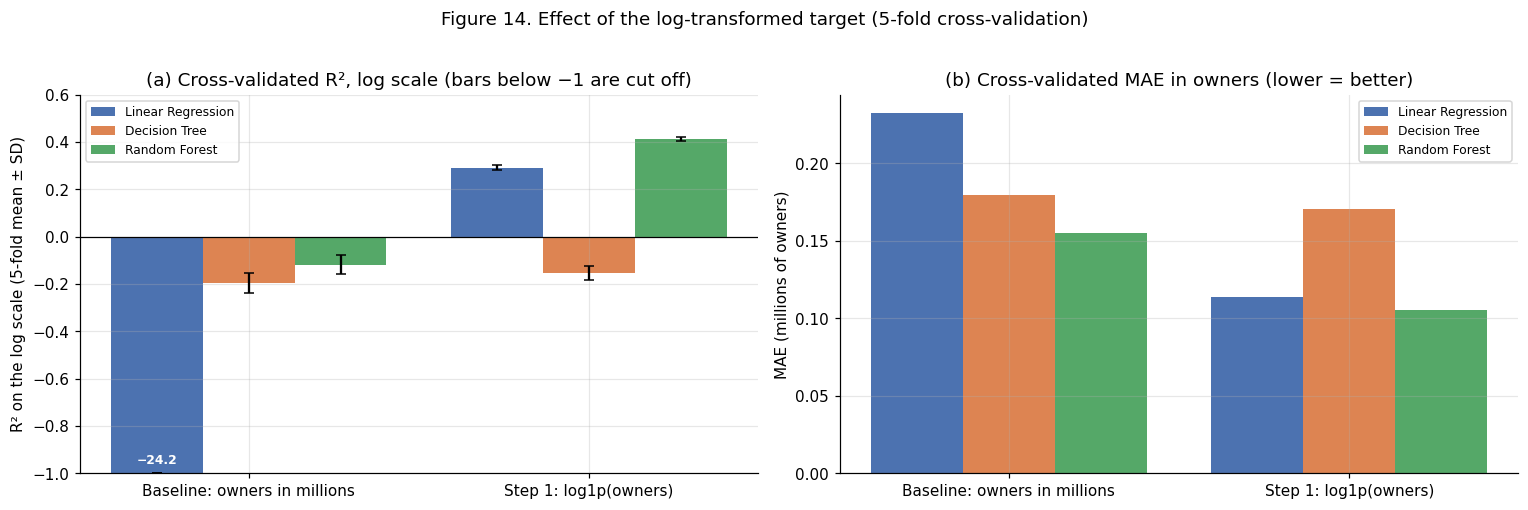

Linear Regression, Baseline: 39.6% of out-of-fold predictions are negative owners
Linear Regression, Step 1: log target: 0.0% of out-of-fold predictions are negative owners


In [4]:
table15 = cv_table([(s, m) for s in ["Baseline", "Step 1: log target"] for m in BASELINE_MODELS])
table15.to_csv(os.path.join(TAB_DIR, "table15_log_target_cv.csv"))

steps, models = ["Baseline", "Step 1: log target"], ["Linear Regression", "Decision Tree", "Random Forest"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x, w = np.arange(len(steps)), 0.27
for i, m in enumerate(models):
    sub = table15.xs(m, level="Model").loc[steps]
    xs = x + (i - 1) * w
    cut = sub["R2 (log)"] < -1
    axes[0].bar(xs, sub["R2 (log)"].clip(lower=-1), w, yerr=sub["R2 (log) SD"].where(~cut, 0), capsize=3,
                color=MODEL_COLORS[m], label=m)
    for xi, value, is_cut in zip(xs, sub["R2 (log)"], cut):
        if is_cut:
            axes[0].text(xi, -0.97, f"{value:.1f}".replace("-", "−"), ha="center", va="bottom", fontsize=8,
                         color="white", fontweight="bold")
    axes[1].bar(xs, sub["MAE (original)"], w, color=MODEL_COLORS[m], label=m)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylim(-1, 0.6)
axes[0].set_ylabel("R² on the log scale (5-fold mean ± SD)")
axes[0].set_title("(a) Cross-validated R², log scale (bars below −1 are cut off)")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].set_ylabel("MAE (millions of owners)")
axes[1].set_title("(b) Cross-validated MAE in owners (lower = better)")
axes[1].legend(fontsize=8, loc="upper right")
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(["Baseline: owners in millions", "Step 1: log1p(owners)"])
fig.suptitle("Figure 14. Effect of the log-transformed target (5-fold cross-validation)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig14_log_target_cv.png"), dpi=150, bbox_inches="tight")
plt.show()

for step in steps:
    negative = (cv_results[(step, "Linear Regression")]["oof_owners"] < 0).mean()
    print(f"Linear Regression, {step}: {negative:.1%} of out-of-fold predictions are negative owners")
cv_view(table15).style.set_caption(
    "Table 15. Owners in millions (baseline) versus log1p(owners) (5-fold cross-validation, mean ± SD)")

**Interpretation.**
- **The log target is the largest single improvement.** Random Forest's cross-validated R² (log) rises from
  −0.119 to 0.414, and Linear Regression's from −24.2 to 0.291. Trained on owners in millions, every model
  scored below zero on the log scale, which is worse than predicting the same value for every game. The
  models over-predict the typical game in order to reduce the squared error on the few largest ones.
- **The typical game is also predicted more accurately in owners.** MAE falls by 32% for Random Forest (0.155
  to 0.105 million) and by 51% for Linear Regression (0.233 to 0.114 million). Linear Regression no longer
  predicts negative owners: 39.6% of its baseline predictions were negative, and none are now.
- **R² on the original scale hardly changes** (Random Forest 0.013 to 0.056; Linear Regression 0.044 to
  −0.007). Converting a log prediction back with expm1 gives the *typical* number of owners. That is far below
  the actual owners of the few blockbusters that dominate this metric. Section 10.5 returns to this.
- **Both tree models still overfit.** The Decision Tree reaches a training R² (log) of 0.996 against −0.154 in
  cross-validation, and Random Forest 0.915 against 0.414. The log target does not stop unrestricted trees
  from memorising individual games, which motivates Step 2.

## 10.4 Step 2: Gradient Boosting instead of Random Forest

**Method.** Gradient boosting also combines many decision trees, but it builds them one after another. Each new
tree is fitted to the errors that the trees before it still make, and its prediction is added with a small
weight (the learning rate). A Random Forest averages 100 deep, independent trees. Gradient boosting instead
adds up many small trees, each with at most 31 leaves and at least 20 games per leaf. It stops adding trees
once the error on 10% of the training data, held aside, stops improving (early stopping). These limits make it
harder to memorise individual games, the main weakness of both tree models so far.

**Settings.** scikit-learn's `HistGradientBoostingRegressor`, which groups each feature's values into at most
255 bins so that it trains quickly on large data. Its defaults are used: learning rate 0.1, up to 100 trees, at
most 31 leaves per tree, at least 20 games per leaf, and early stopping on an internal 10% validation split.
It is trained on log1p(owners), as in Step 1.

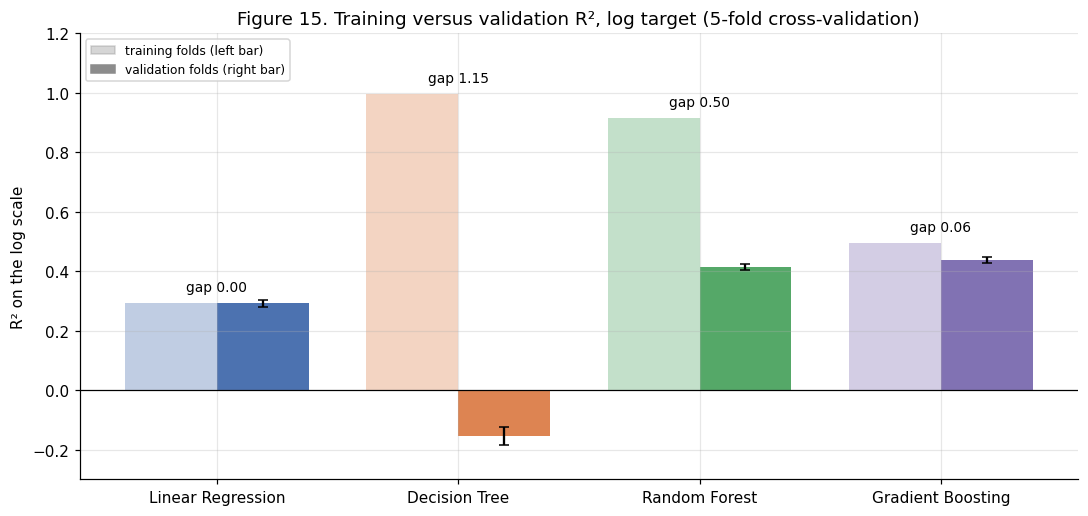

In [5]:
gradient_boosting = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
cv_results[("Step 2: gradient boosting", "Gradient Boosting")] = cross_validate(gradient_boosting, "log")

keys16 = [("Step 1: log target", m) for m in models] + [("Step 2: gradient boosting", "Gradient Boosting")]
table16 = cv_table(keys16)
table16.to_csv(os.path.join(TAB_DIR, "table16_gradient_boosting_cv.csv"))

names = [m for _, m in keys16]
colors = [MODEL_COLORS[m] for m in names]
fig, ax = plt.subplots(figsize=(10, 4.8))
x, w = np.arange(len(names)), 0.38
ax.bar(x - w / 2, table16["Training R2 (log)"], w, color=colors, alpha=0.35)
ax.bar(x + w / 2, table16["R2 (log)"], w, yerr=table16["R2 (log) SD"], capsize=3, color=colors)
for xi, (tr, va) in enumerate(zip(table16["Training R2 (log)"], table16["R2 (log)"])):
    ax.text(xi, max(tr, va) + 0.04, f"gap {tr - va:.2f}", ha="center", fontsize=9)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(-0.3, 1.2)
ax.set_ylabel("R² on the log scale")
ax.legend(handles=[Patch(color=GREY, alpha=0.35, label="training folds (left bar)"),
                   Patch(color=GREY, label="validation folds (right bar)")], fontsize=8, loc="upper left")
ax.set_title("Figure 15. Training versus validation R², log target (5-fold cross-validation)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig15_training_vs_validation.png"), dpi=150)
plt.show()
cv_view(table16).style.set_caption(
    "Table 16. Models on the log target, with Gradient Boosting added (5-fold cross-validation, mean ± SD)")

**Interpretation.**
- **Gradient Boosting is the most accurate model so far.** Its cross-validated R² (log) is 0.437 ± 0.011,
  against 0.414 for Random Forest. It also has the lowest MAE on both scales: 0.651 on the log scale and 0.104
  million owners.
- **It overfits far less.** Its training R² (log) is 0.494, so the gap between training and validation is
  0.06. For Random Forest the gap is 0.50, and for the Decision Tree 1.15 (Figure 15). Small trees, at least
  20 games per leaf and early stopping keep it from memorising individual games. The gain therefore reflects
  better generalisation, not a lucky configuration.
- **No setting was tuned.** The defaults already beat Random Forest. Tuning is left for later, using nested
  cross-validation so that the estimate stays unbiased.
- **Linear Regression does not overfit (gap 0.00) but underfits** (0.291). A single linear equation cannot
  represent effects that do not follow a straight line, such as price (Notebook 6).

## 10.5 Step 3: Converting predictions back to owners (smearing correction)

Converting a log-scale prediction back with expm1 gives the *typical* number of owners (the geometric mean) for
games with those features. For a right-skewed outcome this is systematically below the *average* (the
arithmetic mean). Many similar-looking games sell 10,000 copies and a few sell millions, so the converted
predictions are too small on average. This is why R² on the original scale barely improved in Steps 1 and 2.

**Duan's smearing estimator** is the standard correction. It multiplies every converted prediction by one
constant, the average of exp(residual) over the training data. The fitted model and its log-scale
predictions are exactly those of Step 2, so R² (log) cannot change; only the conversion to owners does. The
correction should help the metrics based on squared error (R² and RMSE on the original scale). It should hurt
MAE, which rewards predicting the typical value.

In [6]:
cv_results[("Step 3: smearing", "Gradient Boosting")] = cross_validate(gradient_boosting, "log", smearing=True)
table17 = cv_table([("Step 2: gradient boosting", "Gradient Boosting"), ("Step 3: smearing", "Gradient Boosting")])
table17.to_csv(os.path.join(TAB_DIR, "table17_smearing_cv.csv"))
print("Smearing factor in each training fold:",
      np.round(cv_results[("Step 3: smearing", "Gradient Boosting")]["smearing"], 3))
cv_view(table17).style.set_caption(
    "Table 17. Gradient Boosting without and with the smearing correction (5-fold cross-validation, mean ± SD)")

Smearing factor in each training fold: [1.97  1.893 1.9   1.949 1.894]


,,R² (log),MAE (log),R² (original),MAE (millions),RMSE (millions),Training R² (log)
Step,Model,,,,,,
Step 2: gradient boosting,Gradient Boosting,0.437 ± 0.011,0.651,0.058 ± 0.029,0.104,1.457,0.494
Step 3: smearing,Gradient Boosting,0.437 ± 0.011,0.651,0.088 ± 0.044,0.115,1.435,0.494


**Interpretation.** The smearing factor is about 1.9 in every fold (1.89–1.97), so every converted prediction
is almost doubled. As expected, R² (log) is unchanged (0.437). R² on the original scale rises from 0.058 to
0.088, and RMSE falls from 1.457 to 1.435 million, while MAE rises from 0.104 to 0.115 million. No single
conversion is best for both kinds of error:
- **expm1 alone** when the question is the typical game (absolute error);
- **expm1 with the smearing correction** when the question is total or average owners (squared error).

Even with the correction, R² on the original scale stays below 0.1. Section 10.7 shows why.

---
## 10.6 Validation on the test set

No step above has used the test set. Each model is now fitted once on the whole training set and evaluated
once on the test set. The baseline models of Notebook 3 are included for comparison.

In [7]:
TEST_KEYS = [("Baseline", "Linear Regression"), ("Baseline", "Random Forest"),
             ("Step 1: log target", "Linear Regression"), ("Step 1: log target", "Random Forest"),
             ("Step 2: gradient boosting", "Gradient Boosting"), ("Step 3: smearing", "Gradient Boosting")]
test_pred, rows = {}, []
for step, name in TEST_KEYS:
    model = gradient_boosting if name == "Gradient Boosting" else BASELINE_MODELS[name]
    target = "raw" if step == "Baseline" else "log"
    fitted = fit(model, X_train, owners_train, target)
    s = smearing_factor(fitted, X_train, owners_train) if step.startswith("Step 3") else 1.0
    test_pred[(step, name)] = predict(fitted, X_test, target, s)
    rows.append({"Step": step, "Model": name, "CV R2 (log)": cv_results[(step, name)]["val"]["R2 (log)"].mean(),
                 **{f"Test {k}": v for k, v in two_scale_metrics(owners_test, *test_pred[(step, name)]).items()}})
    if s != 1.0:
        print(f"Smearing factor from the full training set: {s:.3f}")
table18 = pd.DataFrame(rows).set_index(["Step", "Model"])
table18.to_csv(os.path.join(TAB_DIR, "table18_test_set.csv"))
table18.style.format("{:.3f}").set_caption(
    f"Table 18. Test set performance ({len(test):,} games not used in training); MAE and RMSE in millions of owners")

Smearing factor from the full training set: 1.914


**Interpretation.**
- **The test set confirms the cross-validation.** Gradient Boosting reaches R² (log) 0.426 on the test set,
  against 0.437 in cross-validation. Random Forest (0.404 against 0.414) and Linear Regression (0.282 against
  0.291) on the log target agree just as closely. The results therefore hold for games the models have never
  seen.
- **On the original scale the baseline Random Forest has the best test R² (0.340) and RMSE (1.479 million).**
  Notebook 3 (Section 7.4) showed that this comes from a few blockbusters, such as Counter-Strike 2, happening
  to fall into the test set. Its cross-validated R² (original) is only 0.013, and on the log scale it is worse
  than a constant (−0.117). With the smearing correction, Gradient Boosting reaches a test R² (original) of
  0.126.

**Robustness check: games that share a title.** Some games appear more than once under the same title
(re-releases, editions, remasters). With random folds, one copy can sit in the training folds and another in
the validation fold, which could make the results look better than they are. The check repeats the
cross-validation with folds grouped by normalised title, so that all games with the same title fall into the
same fold.

In [8]:
def title_key(names):
    """Normalised title: lower case, letters and digits only."""
    k = names.fillna("").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return k.where(k != "", "row" + pd.Series(range(len(k)), index=k.index).astype(str))


groups = title_key(train["name"])
print(f"{len(train):,} training games have {groups.nunique():,} distinct normalised titles")
schemes = {"Random folds (as above)": folds,
           "Folds grouped by title": list(GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                                          .split(X_train, groups=groups))}
rows = []
for scheme, scheme_folds in schemes.items():
    fold_metrics = []
    for tr, va in scheme_folds:
        m = fit(gradient_boosting, X_train.iloc[tr], owners_train[tr], "log")
        s = smearing_factor(m, X_train.iloc[tr], owners_train[tr])
        fold_metrics.append(two_scale_metrics(owners_train[va], *predict(m, X_train.iloc[va], "log", s)))
    fm = pd.DataFrame(fold_metrics)
    rows.append({"Folds": scheme, "R2 (log)": fm["R2 (log)"].mean(), "R2 (log) SD": fm["R2 (log)"].std(),
                 "R2 (original)": fm["R2 (original)"].mean(), "R2 (original) SD": fm["R2 (original)"].std()})
table19 = pd.DataFrame(rows).set_index("Folds")
table19.to_csv(os.path.join(TAB_DIR, "table19_grouped_cv.csv"))
table19.style.format("{:.3f}").set_caption(
    "Table 19. Gradient Boosting with smearing: random folds versus folds grouped by title (5-fold cross-validation)")

61,381 training games have 60,614 distinct normalised titles


,R2 (log),R2 (log) SD,R2 (original),R2 (original) SD
Folds,,,,
Random folds (as above),0.437,0.011,0.088,0.044
Folds grouped by title,0.434,0.012,0.158,0.128


**Interpretation.** The 61,381 training games have 60,614 distinct normalised titles, so few titles occur
more than once. Grouping the folds by title changes R² (log) by less than 0.005 (0.434 against 0.437), so
duplicated titles do not inflate the result. R² on the original scale moves more (0.158 ± 0.128 against 0.088 ±
0.044). Its large fold-to-fold SD shows again that this metric depends on which blockbusters fall into each
fold.

## 10.7 Where the errors remain

Figure 16 repeats Notebook 3's Figure 11 for the new model. It shows each test game's prediction against its
actual owners, and the mean prediction for each owner range.

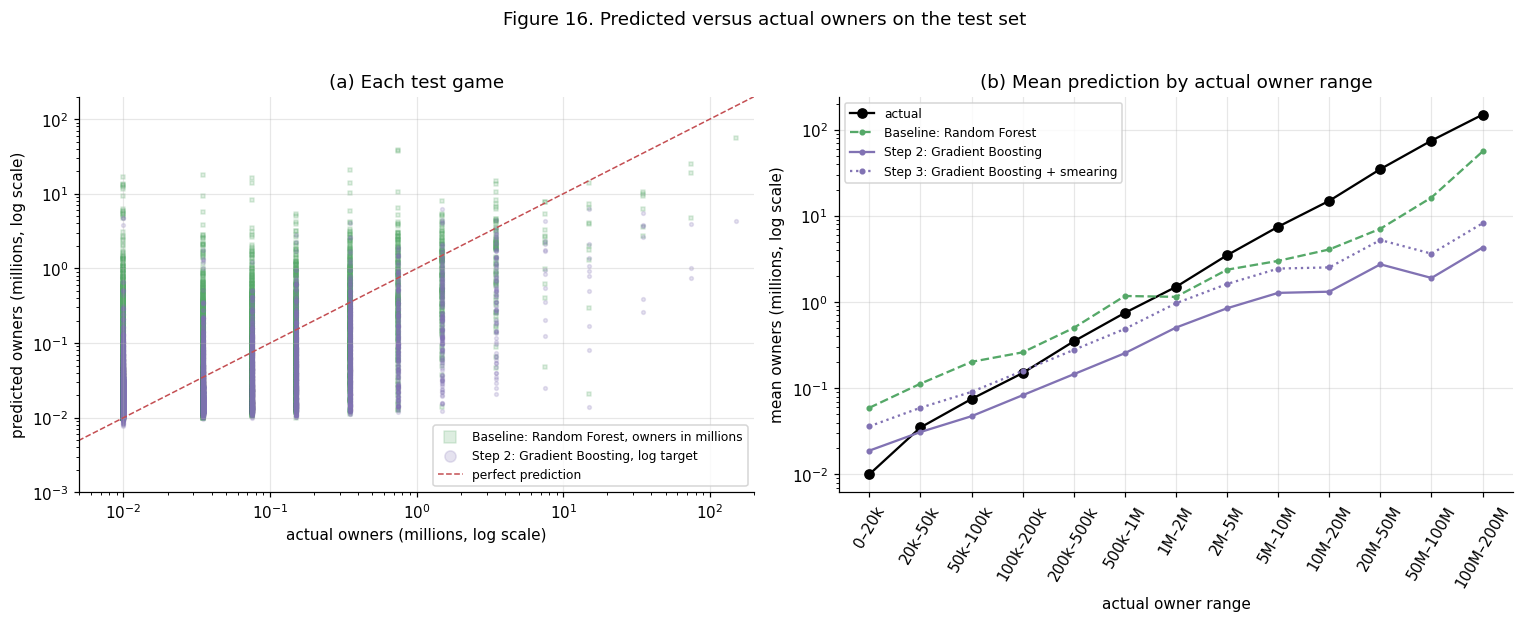

Gradient Boosting predictions range from 0.008 to 6.2 million owners; actual owners range from 0.01 to 150 million


In [9]:
actual_m = owners_test / 1e6
rf_owners, _ = test_pred[("Baseline", "Random Forest")]
gb_owners, gb_log = test_pred[("Step 2: gradient boosting", "Gradient Boosting")]
gb_smear_owners, _ = test_pred[("Step 3: smearing", "Gradient Boosting")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
ax.scatter(actual_m, np.clip(rf_owners / 1e6, 1e-3, None), s=6, alpha=0.2, color=GREEN, marker="s",
           label="Baseline: Random Forest, owners in millions")
ax.scatter(actual_m, gb_owners / 1e6, s=6, alpha=0.2, color=PURPLE, label="Step 2: Gradient Boosting, log target")
lims = [1e-3, 200]
ax.plot(lims, lims, color=RED, ls="--", lw=1, label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(5e-3, 200)
ax.set_ylim(*lims)
ax.set_xlabel("actual owners (millions, log scale)")
ax.set_ylabel("predicted owners (millions, log scale)")
ax.set_title("(a) Each test game")
ax.legend(markerscale=3, fontsize=8)

order = test.drop_duplicates("estimated_owners").sort_values("owners")["estimated_owners"]
ranges = test["estimated_owners"]
by_range = pd.DataFrame({
    "actual": pd.Series(actual_m).groupby(ranges).mean(),
    "Baseline: Random Forest": pd.Series(rf_owners / 1e6).groupby(ranges).mean(),
    "Step 2: Gradient Boosting": pd.Series(gb_owners / 1e6).groupby(ranges).mean(),
    "Step 3: Gradient Boosting + smearing": pd.Series(gb_smear_owners / 1e6).groupby(ranges).mean(),
}).reindex(order)
ax = axes[1]
xs = np.arange(len(by_range))
ax.plot(xs, by_range["actual"], color="black", marker="o", label="actual")
ax.plot(xs, by_range["Baseline: Random Forest"], color=GREEN, marker=".", ls="--", label="Baseline: Random Forest")
ax.plot(xs, by_range["Step 2: Gradient Boosting"], color=PURPLE, marker=".", label="Step 2: Gradient Boosting")
ax.plot(xs, by_range["Step 3: Gradient Boosting + smearing"], color=PURPLE, marker=".", ls=":",
        label="Step 3: Gradient Boosting + smearing")
ax.set_yscale("log")
ax.set_xticks(xs)
ax.set_xticklabels([range_label(o) for o in by_range.index], rotation=60)
ax.set_xlabel("actual owner range")
ax.set_ylabel("mean owners (millions, log scale)")
ax.set_title("(b) Mean prediction by actual owner range")
ax.legend(fontsize=8)
fig.suptitle("Figure 16. Predicted versus actual owners on the test set", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig16_predicted_vs_actual_log_target.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"Gradient Boosting predictions range from {gb_owners.min() / 1e6:.3f} to {gb_owners.max() / 1e6:.1f} million "
      f"owners; actual owners range from {actual_m.min():.2f} to {actual_m.max():.0f} million")

In [10]:
err = pd.DataFrame({"range": ranges, "log_error": gb_log - np.log1p(owners_test),
                    "sq_error": (gb_owners / 1e6 - actual_m) ** 2})
table20 = err.groupby("range").agg(games=("log_error", "size"), mean_log_error=("log_error", "mean"),
                                   sq_error=("sq_error", "sum")).reindex(order)
table20["share of games"] = table20["games"] / table20["games"].sum()
table20["share of squared error"] = table20["sq_error"] / table20["sq_error"].sum()
table20["typical prediction"] = [f"×{np.exp(e):.1f} (over)" if e >= 0 else f"÷{np.exp(-e):.1f} (under)"
                                 for e in table20["mean_log_error"]]
table20 = table20[["games", "share of games", "mean_log_error", "typical prediction", "share of squared error"]]
table20.index = [range_label(r) for r in table20.index]
table20.index.name = "actual owner range"
table20.to_csv(os.path.join(TAB_DIR, "table20_errors_by_owner_range.csv"))
table20.style.format({"games": "{:,}", "share of games": "{:.1%}", "mean_log_error": "{:+.2f}",
                      "share of squared error": "{:.1%}"}) \
    .set_caption("Table 20. Gradient Boosting (Step 2) errors by actual owner range, test set "
                 "(mean log error > 0 = over-prediction)")

,games,share of games,mean_log_error,typical prediction,share of squared error
actual owner range,,,,,
0–20k,"10,769",70.2%,+0.43,×1.5 (over),0.1%
20k–50k,"1,995",13.0%,-0.50,÷1.6 (under),0.0%
50k–100k,959,6.2%,-0.90,÷2.5 (under),0.0%
100k–200k,645,4.2%,-1.31,÷3.7 (under),0.1%
200k–500k,515,3.4%,-1.67,÷5.3 (under),0.1%
500k–1M,208,1.4%,-1.90,÷6.7 (under),0.2%
1M–2M,148,1.0%,-1.97,÷7.1 (under),0.5%
2M–5M,75,0.5%,-2.19,÷8.9 (under),1.3%
5M–10M,12,0.1%,-2.43,÷11.4 (under),1.0%


In [11]:
largest = test.assign(actual=actual_m, predicted=gb_owners / 1e6)
largest = largest.assign(abs_error=(largest["predicted"] - largest["actual"]).abs()).nlargest(10, "abs_error")
table21 = pd.DataFrame({
    "Game": largest["name"], "Release year": largest["release_year"], "Price ($)": largest["price"],
    "Free-to-play genre": largest["genre_Free_To_Play"].map({1: "yes", 0: "no"}),
    "Languages": largest["n_languages"], "Actual owners (M)": largest["actual"],
    "Predicted (M)": largest["predicted"], "Actual ÷ predicted": largest["actual"] / largest["predicted"],
}).reset_index(drop=True)
table21.index += 1
table21.to_csv(os.path.join(TAB_DIR, "table21_largest_errors_test.csv"))
big = owners_test >= 10_000_000
sq = (gb_owners / 1e6 - actual_m) ** 2
print(f"{big.sum()} test games have 10M+ owners ({big.mean():.2%} of the test set). They produce "
      f"{sq[big].sum() / sq.sum():.1%} of Gradient Boosting's squared error in owners, and "
      f"{(gb_owners[big] < owners_test[big]).mean():.0%} of them are under-predicted.")
table21.style.format({"Price ($)": "{:.2f}", "Actual owners (M)": "{:.0f}", "Predicted (M)": "{:.2f}",
                      "Actual ÷ predicted": lambda v: f"{v:.0f}×" if v >= 1 else f"{v:.2f}×"}) \
    .set_caption("Table 21. The ten largest errors in owners (Gradient Boosting, Step 2, test set)")

20 test games have 10M+ owners (0.13% of the test set). They produce 96.6% of Gradient Boosting's squared error in owners, and 100% of them are under-predicted.


,Game,Release year,Price ($),Free-to-play genre,Languages,Actual owners (M),Predicted (M),Actual ÷ predicted
1,Counter-Strike 2,2012,0.00,yes,29,150,4.30,35×
2,Palworld,2024,29.99,no,17,75,0.74,101×
3,Grand Theft Auto V Legacy,2015,0.00,no,13,75,1.00,75×
4,Left 4 Dead 2,2009,9.99,no,28,75,3.97,19×
5,Brawlhalla,2017,39.99,yes,13,35,0.26,135×
6,ARK: Survival Evolved,2017,14.99,no,21,35,0.39,89×
7,World of Warships,2017,0.00,yes,18,35,2.63,13×
8,Warframe,2013,0.00,yes,15,35,3.73,9×
9,Rust,2018,39.99,no,25,35,3.85,9×
10,Dead by Daylight,2016,19.99,no,15,35,5.61,6×


**Interpretation.**
- **Figure 16a.** The baseline Random Forest spreads its predictions for small games far above the diagonal.
  Gradient Boosting's predictions for small games sit much closer to it. However, it compresses all
  predictions into a narrow band, from 0.008 to 6.2 million owners, while actual owners reach 150 million.
- **Figure 16b and Table 20.** Gradient Boosting over-predicts the lowest range (70% of games) by a factor
  of about 1.5 and under-predicts every higher range, more strongly the larger the game. The factor is 1.6
  for 20k–50k owners, about 7 for 1–2M and 21–52 for 10M+. When the features cannot distinguish a future hit
  from similar-looking games, the model predicts close to their typical outcome (regression towards the
  mean). The smearing correction lifts every prediction by the same factor (×1.9). This moves the large
  ranges closer and the smallest range further away.
- **Blockbusters still dominate the squared error.** All 20 test games with 10M+ owners (0.13% of the test
  set) are under-predicted, and they produce 96.6% of the squared error in owners. This is why R² on the
  original scale stays low.
- **The largest misses (Table 21)** are free-to-play and online multiplayer games (Counter-Strike 2,
  Brawlhalla, World of Warships, Warframe) and major hits or franchises (Palworld, Grand Theft Auto V, Left 4
  Dead 2, ARK, Rust, Dead by Daylight). What made them hits is largely missing from the store page: network
  effects, word of mouth after launch, franchise strength and marketing budgets.
- Some store fields reflect the 2025 data snapshot rather than launch day. For example, Brawlhalla is listed
  at $39.99 despite its free-to-play tag.

## 10.8 Which features matter

**Permutation importance** measures how much R² (log) drops when one feature's values are shuffled across
games. Shuffling breaks the feature's link with owners and leaves everything else intact. It is computed on
the five validation folds of the cross-validation (5 repeats each), so the test set is not used. Correlated
features share credit (for example, supported languages and full-audio languages), so related features are
also shuffled together as groups.

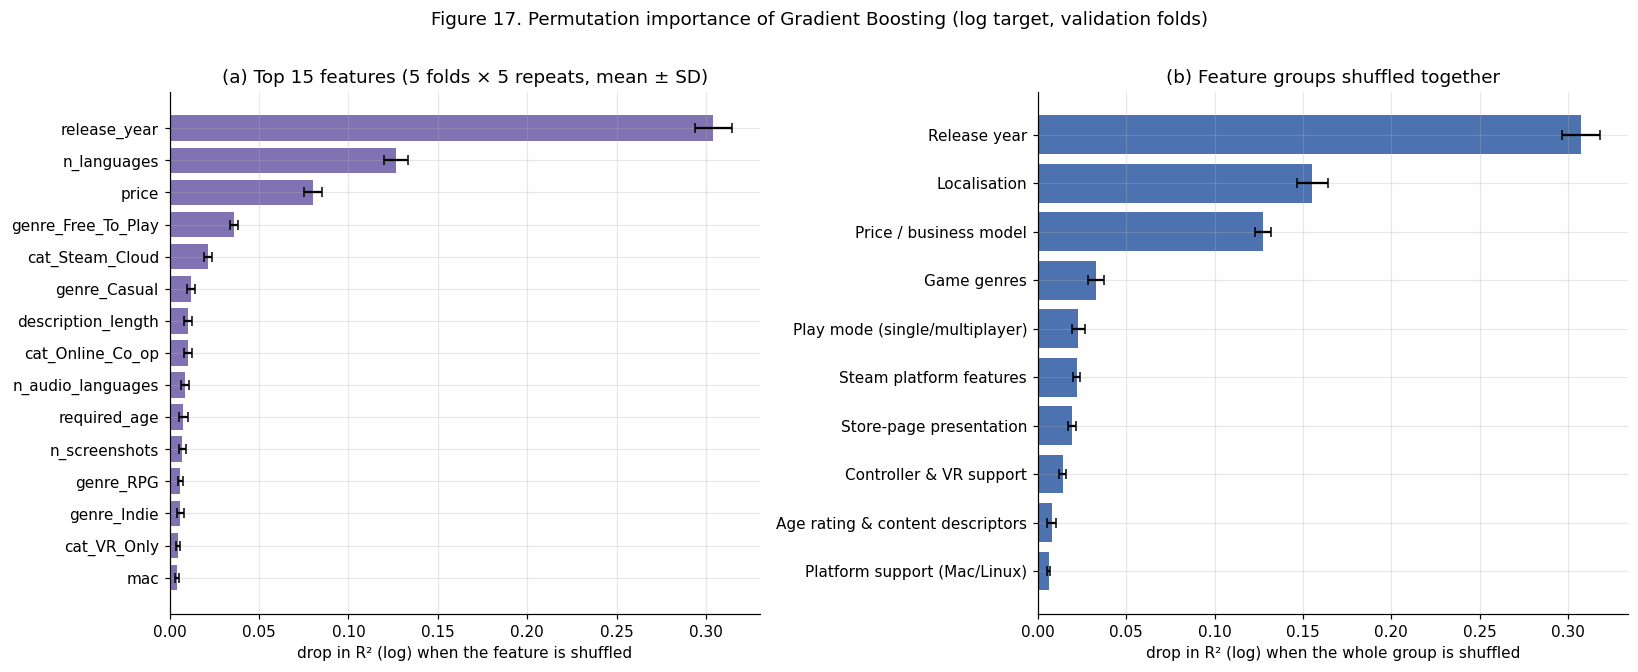

In [12]:
FEATURE_GROUPS = {
    "Price / business model": ["price", "genre_Free_To_Play"],
    "Release year": ["release_year"],
    "Localisation": ["n_languages", "n_audio_languages"],
    "Platform support (Mac/Linux)": ["mac", "linux"],
    "Store-page presentation": ["n_screenshots", "description_length"],
    "Age rating & content descriptors": ["required_age", "genre_Violent", "genre_Gore", "genre_Nudity"],
    "Game genres": ["genre_Indie", "genre_Casual", "genre_Action", "genre_Adventure", "genre_Simulation",
                    "genre_Strategy", "genre_RPG", "genre_Sports", "genre_Racing", "genre_Massively_Multiplayer",
                    "genre_Education"],
    "Play mode (single/multiplayer)": ["cat_Single_player", "cat_Multi_player", "cat_PvP", "cat_Co_op",
                                       "cat_Online_PvP", "cat_Online_Co_op", "cat_Shared_Split_Screen",
                                       "cat_Shared_Split_Screen_PvP", "cat_Shared_Split_Screen_Co_op"],
    "Controller & VR support": ["cat_Full_controller_support", "cat_Partial_Controller_Support",
                                "cat_Tracked_Controller_Support", "cat_VR_Only"],
    "Steam platform features": ["cat_Steam_Cloud", "cat_Steam_Leaderboards", "cat_Stats",
                                "cat_Includes_level_editor", "cat_Captions_available"],
}
assert sorted(c for cols in FEATURE_GROUPS.values() for c in cols) == sorted(FEATURES)


def grouped_permutation(fitted, X, y, n_repeats, seed):
    """Drop in R² (log) when all features of a group are shuffled together."""
    rng = np.random.default_rng(seed)
    base = r2_score(y, fitted.predict(X))
    out = {}
    for g, cols in FEATURE_GROUPS.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]
            drops.append(base - r2_score(y, fitted.predict(Xp)))
        out[g] = drops
    return out


y_log_train = np.log1p(owners_train)
per_feature = {c: [] for c in FEATURES}
per_group = {g: [] for g in FEATURE_GROUPS}
for i, (tr, va) in enumerate(folds):
    m = fit(gradient_boosting, X_train.iloc[tr], owners_train[tr], "log")
    X_va, y_va = X_train.iloc[va], y_log_train[va]
    pi = permutation_importance(m, X_va, y_va, scoring="r2", n_repeats=5, random_state=RANDOM_STATE + i, n_jobs=1)
    for j, c in enumerate(FEATURES):
        per_feature[c].extend(pi.importances[j])
    for g, drops in grouped_permutation(m, X_va, y_va, 5, RANDOM_STATE + i).items():
        per_group[g].extend(drops)

importance = pd.DataFrame({"level": "feature", "name": FEATURES,
                           "importance": [np.mean(per_feature[c]) for c in FEATURES],
                           "SD": [np.std(per_feature[c], ddof=1) for c in FEATURES]})
group_importance = pd.DataFrame({"level": "group", "name": list(FEATURE_GROUPS),
                                 "importance": [np.mean(per_group[g]) for g in FEATURE_GROUPS],
                                 "SD": [np.std(per_group[g], ddof=1) for g in FEATURE_GROUPS]})
pd.concat([importance, group_importance]).to_csv(os.path.join(TAB_DIR, "table22_permutation_importance.csv"),
                                                 index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = importance.nlargest(15, "importance").iloc[::-1]
axes[0].barh(top["name"], top["importance"], xerr=top["SD"], color=PURPLE, capsize=3)
axes[0].set_xlabel("drop in R² (log) when the feature is shuffled")
axes[0].set_title("(a) Top 15 features (5 folds × 5 repeats, mean ± SD)")
g = group_importance.sort_values("importance")
axes[1].barh(g["name"], g["importance"], xerr=g["SD"], color=BLUE, capsize=3)
axes[1].set_xlabel("drop in R² (log) when the whole group is shuffled")
axes[1].set_title("(b) Feature groups shuffled together")
fig.suptitle("Figure 17. Permutation importance of Gradient Boosting (log target, validation folds)", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig17_permutation_importance.png"), dpi=150, bbox_inches="tight")
plt.show()

Release year may act mainly as a proxy for time on sale (Notebook 3, issue 7). If the model had learned
nothing else, it would explain nothing within a single release year. Table 23 therefore computes R² (log) on
the test games of each release year separately.

In [13]:
within = []
for year, idx in test.groupby("release_year").groups.items():
    idx = idx.to_numpy()
    if len(idx) >= 300:
        within.append({"Release year": year, "Test games": len(idx),
                       "R² (log) within the year": r2_score(np.log1p(owners_test[idx]), gb_log[idx])})
table23 = pd.DataFrame(within).set_index("Release year")
table23.to_csv(os.path.join(TAB_DIR, "table23_within_year_r2.csv"))
print(f"Games-weighted mean R² (log) within a release year: "
      f"{np.average(table23['R² (log) within the year'], weights=table23['Test games']):.3f}")
table23.T.style.format("{:.3f}", subset=pd.IndexSlice["R² (log) within the year", :]) \
    .format("{:,.0f}", subset=pd.IndexSlice["Test games", :]) \
    .set_caption("Table 23. Gradient Boosting (Step 2) R² (log) within each release year, test set (years with 300+ test games)")

Games-weighted mean R² (log) within a release year: 0.317


Release year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Test games,311,495,793,"1,139","1,550","1,339","1,740","1,946","1,948","2,313","1,406"
R² (log) within the year,0.249,0.244,0.346,0.384,0.358,0.371,0.338,0.338,0.294,0.236,0.303


**Interpretation.**
- **Release year is the strongest predictor** (drop in R² of 0.304). It mostly measures time on sale and
  market crowding: older games have had longer to collect owners and faced fewer competitors. It says little
  about the game itself (Notebook 3, issue 7).
- **The model learns more than the release year.** Within a single release year it still explains 24–38% of
  the variance in log owners (0.32 on average, Table 23).
- **Localisation (0.155 as a group) and price and business model (0.127) come next**, followed by genres, play
  mode and Steam platform features. Supported languages is the second most important single feature. It was
  also the most important feature of the baseline Random Forest (Notebook 3, Figure 9).
- **These are predictive associations, not causal effects.** A larger budget, for example, can lead both to
  more translations and to more sales.

---
## 10.9 Findings and decision

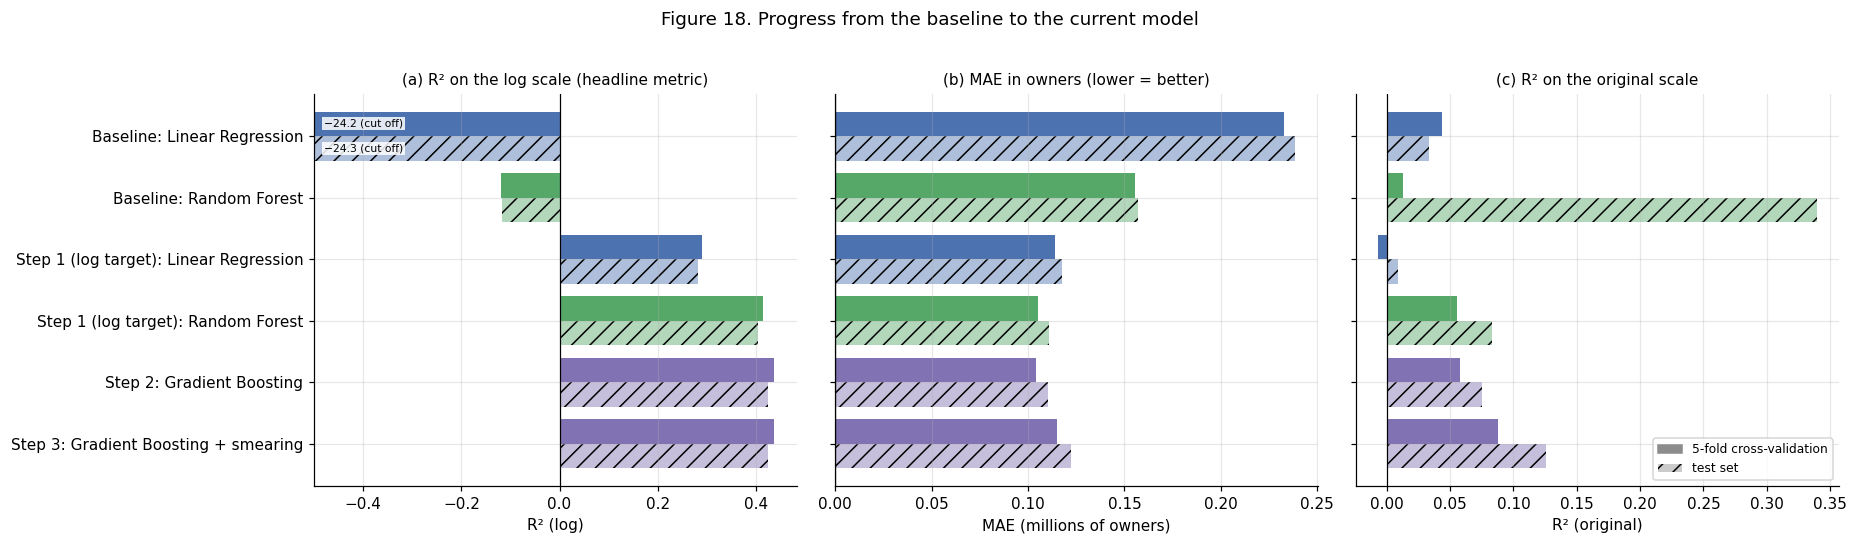

,CV R² (log),Test R² (log),CV MAE (millions),Test MAE (millions),CV R² (original),Test R² (original)
Model,,,,,,
Baseline: Linear Regression,-24.198 ± 0.683,-24.271,0.233,0.238,0.044,0.033
Baseline: Random Forest,-0.119 ± 0.040,-0.117,0.155,0.157,0.013,0.340
Step 1 (log target): Linear Regression,0.291 ± 0.010,0.282,0.114,0.118,-0.007,0.009
Step 1 (log target): Random Forest,0.414 ± 0.009,0.404,0.105,0.111,0.056,0.083
Step 2: Gradient Boosting,0.437 ± 0.011,0.425,0.104,0.110,0.058,0.075
Step 3: Gradient Boosting + smearing,0.437 ± 0.011,0.425,0.115,0.123,0.088,0.126


In [14]:
SHORT = {("Baseline", "Linear Regression"): "Baseline: Linear Regression",
         ("Baseline", "Random Forest"): "Baseline: Random Forest",
         ("Step 1: log target", "Linear Regression"): "Step 1 (log target): Linear Regression",
         ("Step 1: log target", "Random Forest"): "Step 1 (log target): Random Forest",
         ("Step 2: gradient boosting", "Gradient Boosting"): "Step 2: Gradient Boosting",
         ("Step 3: smearing", "Gradient Boosting"): "Step 3: Gradient Boosting + smearing"}
rows = []
for key in TEST_KEYS:
    val = cv_results[key]["val"]
    rows.append({"Model": SHORT[key],
                 "CV R² (log)": f"{val['R2 (log)'].mean():.3f} ± {val['R2 (log)'].std():.3f}",
                 "Test R² (log)": table18.loc[key, "Test R2 (log)"],
                 "CV MAE (millions)": val["MAE (original)"].mean(), "Test MAE (millions)": table18.loc[key, "Test MAE (original)"],
                 "CV R² (original)": val["R2 (original)"].mean(), "Test R² (original)": table18.loc[key, "Test R2 (original)"]})
table24 = pd.DataFrame(rows).set_index("Model")
table24.to_csv(os.path.join(TAB_DIR, "table24_progress_summary.csv"))

labels = [SHORT[k] for k in TEST_KEYS]
colors = [MODEL_COLORS[k[1]] for k in TEST_KEYS]
panels = [("R2 (log)", "Test R2 (log)", "R² (log)", "(a) R² on the log scale (headline metric)", -0.5),
          ("MAE (original)", "Test MAE (original)", "MAE (millions of owners)", "(b) MAE in owners (lower = better)", None),
          ("R2 (original)", "Test R2 (original)", "R² (original)", "(c) R² on the original scale", None)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
y = np.arange(len(labels))
for ax, (cv_col, test_col, xlabel, title, lower) in zip(axes, panels):
    cv_vals = np.array([cv_results[k]["val"][cv_col].mean() for k in TEST_KEYS])
    test_vals = np.array([table18.loc[k, test_col] for k in TEST_KEYS])
    for vals, offset, alpha, hatch in [(cv_vals, -0.2, 1.0, None), (test_vals, 0.2, 0.45, "//")]:
        shown = vals if lower is None else np.maximum(vals, lower)
        ax.barh(y + offset, shown, 0.4, color=colors, alpha=alpha, hatch=hatch)
        for yi, v, s in zip(y + offset, vals, shown):
            if v != s:
                ax.text(lower + 0.02, yi, f"{v:.1f} (cut off)".replace("-", "−"), va="center", fontsize=7,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1))
    ax.axvline(0, color="black", lw=0.8)
    if lower is not None:
        ax.set_xlim(left=lower)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=10)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()
axes[2].legend(handles=[Patch(color=GREY, label="5-fold cross-validation"),
                        Patch(facecolor=GREY, alpha=0.45, hatch="//", label="test set")], fontsize=8, loc="lower right")
fig.suptitle("Figure 18. Progress from the baseline to the current model", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig18_progress_summary.png"), dpi=150, bbox_inches="tight")
plt.show()
table24.style.format({c: "{:.3f}" for c in table24.columns if c != "CV R² (log)"}) \
    .set_caption("Table 24. Progress summary: cross-validation (mean of 5 folds) and test set")

**Findings.**
1. **The log target is the largest single gain.** It turns models that were worse than a constant on the log
   scale into useful ones (Random Forest −0.119 → 0.414). It also halves Linear Regression's absolute error and
   removes its negative predictions.
2. **Gradient Boosting is the best model so far**, with default settings. Its cross-validated R² (log) is 0.437
   ± 0.011 and its test R² (log) 0.426. It is also the least overfitted tree model: its training–validation gap
   is 0.06, against 0.50 for Random Forest. Compared with the baseline Random Forest, cross-validated MAE falls
   by a third (0.155 → 0.104 million owners).
3. **The two R² scales answer different questions.** On the log scale the model explains 44% of the variance,
   which describes the typical game. On the original scale R² stays below 0.1 (0.088 with the smearing
   correction), because 20 test games (0.13%) produce 97% of the squared error.
4. **Store-page information cannot size a blockbuster.** Every test game with 10M+ owners is under-predicted,
   typically by a factor of 20 to 50.
5. **Release year, localisation and price are the most informative features.** The model still explains about
   a third of the variance among games released in the same year.

**Status of the baseline issues (Notebook 3, Section 8.3).**

| # | Issue | Status |
|---|---|---|
| 1 | The target's skew dominates fitting and metrics | **Addressed** by the log target; it still limits R² on the original scale |
| 2 | Evaluation is unstable | **Addressed on the log scale** (fold SD 0.011); the original scale remains unstable (SD 0.044–0.128) |
| 3 | Linear Regression predicts negative owners | **Solved** (no negative predictions) |
| 4 | The Decision Tree overfits | Still overfits with default settings; **superseded** by Gradient Boosting |
| 5 | Random Forest overfits | **Superseded** by Gradient Boosting (gap 0.50 → 0.06) |
| 6 | MAPE is not informative | **Replaced** by MAE on the log scale |
| 7 | Release year mixes time on sale with game characteristics | **Open.** Partly checked (within-year R² 0.24–0.38); next step: chronological validation |
| 8 | The feature set covers basic store-page fields only | **Open.** Next step: new pre-release features |

**Decision.** Gradient Boosting on log1p(owners) replaces the baseline Random Forest as the reference model for
all further modifications. R² on the log scale is the headline metric, always reported with MAE and RMSE in
owners. The conversion back to owners depends on the question: expm1 alone for the typical game, and the
smearing correction for totals.

**Next steps.**
1. **Notebook 6:** apply the second parent paper's approach (separate paid and free-to-play models, price bands
   and percentage effects).
2. **Chronological validation** (train on earlier releases, test on 2022–2024), to measure how well the model
   forecasts future games (issue 7).
3. **New pre-release features**, one group at a time (issue 8): developer and publisher track record computed
   only from earlier releases, franchise or sequel markers, and store-page lead time.
4. **Modest tuning** of Gradient Boosting with nested cross-validation.